# E1 · Laboratorio estadístico: pronóstico del costo de construcción — ObraPrecio

**Pregunta:** ¿se puede anticipar cuánto costará construir en Colima dentro de 1, 3, 6 y 12 meses, y con qué margen de error?

**Serie:** índice general de costo de construcción residencial de Colima (INEGI, INPP, base julio 2019 = 100), mensual, de enero de 2004 a julio de 2025. Sale de la capa oro (`data/oro/obraprecio_ciudad_mensual.csv`), ya validada por la puerta de calidad. Se repite el ejercicio con el índice Nacional para comprobar que las conclusiones no dependen de una sola ciudad.

| Sección | Criterio de la rúbrica |
|---|---|
| 1 | Caracterización de la serie |
| 2 | Estacionariedad, ACF y PACF |
| 3 | Cuatro modelos: suavizamiento simple, Holt, Holt-Winters y ARIMA/SARIMA |
| 4 | Evaluación con MAE, RMSE y MAPE |
| 5 | Diagnóstico de residuos (Ljung-Box) |
| 6 | Pronóstico y conclusiones |

El código de los modelos está en `laboratorio/modelos.py` y tiene sus pruebas en `tests/test_laboratorio.py`.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf, pacf

RAIZ = Path.cwd() if (Path.cwd() / "laboratorio").exists() else Path.cwd().parents[1]
sys.path.insert(0, str(RAIZ))
from laboratorio import modelos as M

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
COLOR = {"ses": "#2a78d6", "holt": "#eb6834", "holt_winters": "#1baf7a", "sarima": "#6250d6", "ingenuo": "#898781", "deriva": "#898781"}
ESTILO = {"ingenuo": ":", "deriva": "--"}
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "text.color": "#0b0b0b", "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 9.5, "lines.linewidth": 2, "figure.dpi": 110})

tabla = pd.read_csv(RAIZ / "data/oro/obraprecio_ciudad_mensual.csv", parse_dates=["fecha"])
y = M.serie_mensual(tabla, "colima"); nac = M.serie_mensual(tabla, "nacional")
H = 12; ent, pru = y.iloc[:-H], y.iloc[-H:]
print(f"Colima: {len(y)} meses, {y.index[0]:%Y-%m} a {y.index[-1]:%Y-%m} | entrenamiento hasta {ent.index[-1]:%Y-%m} ({len(ent)}) | prueba {pru.index[0]:%Y-%m} a {pru.index[-1]:%Y-%m} ({H})")

Colima: 259 meses, 2004-01 a 2025-07 | entrenamiento hasta 2024-07 (247) | prueba 2024-08 a 2025-07 (12)


## 1. Caracterización de la serie

In [2]:
var_m = y.pct_change() * 100; var_a = y.pct_change(12) * 100
desc = pd.DataFrame({"índice": y.describe(), "variación mensual %": var_m.describe(), "variación anual %": var_a.describe()}).T
desc["asimetría"] = [y.skew(), var_m.skew(), var_a.skew()]; desc["curtosis"] = [y.kurt(), var_m.kurt(), var_a.kurt()]
display(desc)
stl = M.descomponer(y); fuerza = M.fuerza_tendencia_estacionalidad(stl); fz_nac = M.fuerza_tendencia_estacionalidad(M.descomponer(nac))
print(f"Fuerza de la tendencia: Colima {fuerza['tendencia']:.3f}, Nacional {fz_nac['tendencia']:.3f} | fuerza de la estacionalidad: Colima {fuerza['estacionalidad']:.3f}, Nacional {fz_nac['estacionalidad']:.3f}  (0 = nula, 1 = total)")
print(f"Crecimiento total 2004-01 a 2025-07: {(y.iloc[-1] / y.iloc[0] - 1) * 100:.0f} % | promedio anual compuesto: {((y.iloc[-1] / y.iloc[0]) ** (12 / (len(y) - 1)) - 1) * 100:.2f} %")

,count,mean,std,min,25%,50%,75%,max,asimetría,curtosis
índice,259.000,85.211,32.258,43.961,59.539,71.014,101.165,153.426,0.805,-0.614
variación mensual %,258.000,0.490,1.261,-2.360,-0.142,0.193,0.860,8.302,2.558,11.438
variación anual %,247.000,5.781,4.946,-5.146,2.266,5.348,8.694,19.057,0.488,-0.153


Fuerza de la tendencia: Colima 0.998, Nacional 0.998 | fuerza de la estacionalidad: Colima 0.205, Nacional 0.159  (0 = nula, 1 = total)
Crecimiento total 2004-01 a 2025-07: 246 % | promedio anual compuesto: 5.94 %


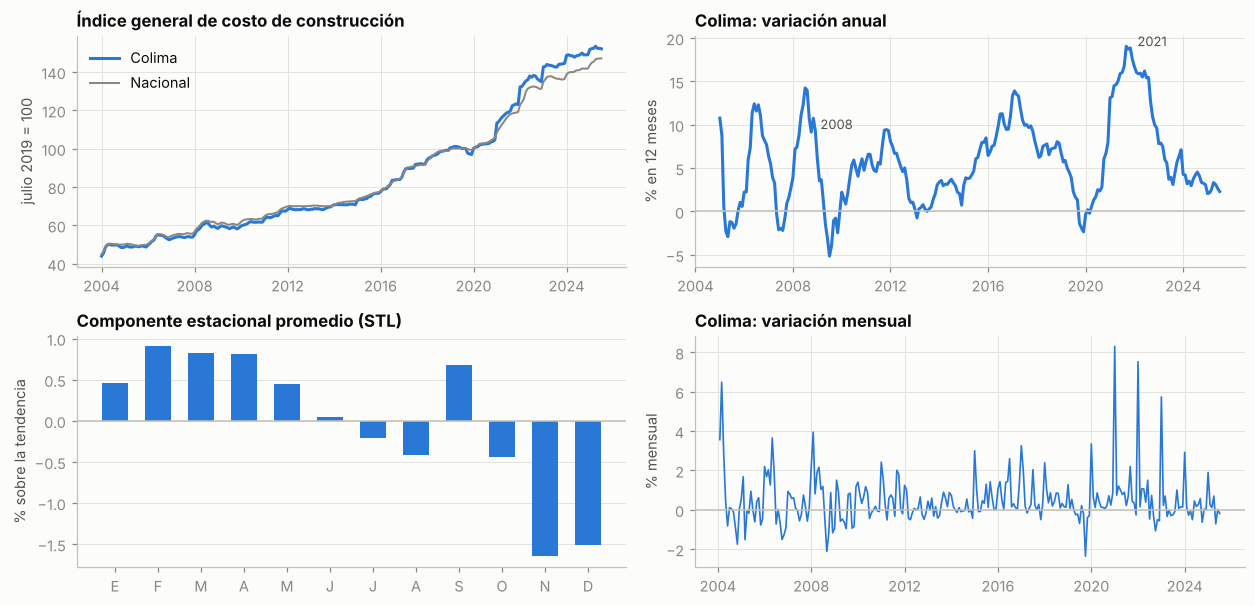

Componente estacional promedio por mes (%): {1: 0.46, 2: 0.91, 3: 0.82, 4: 0.82, 5: 0.45, 6: 0.04, 7: -0.21, 8: -0.42, 9: 0.68, 10: -0.44, 11: -1.65, 12: -1.51}


In [3]:
fig, axs = plt.subplots(2, 2, figsize=(11.5, 5.6))
ax = axs[0, 0]; ax.plot(y, color="#2a78d6", label="Colima"); ax.plot(nac, color="#898781", lw=1.3, label="Nacional")
ax.set(title="Índice general de costo de construcción", ylabel="julio 2019 = 100"); ax.legend(frameon=False)
ax = axs[0, 1]; ax.plot(var_a, color="#2a78d6"); ax.axhline(0, color="#c3c2b7", lw=1); ax.set(title="Colima: variación anual", ylabel="% en 12 meses")
for f, txt in (("2008-10-01", "2008"), ("2021-10-01", "2021")): ax.annotate(txt, (pd.Timestamp(f), var_a[f]), textcoords="offset points", xytext=(6, 2), fontsize=8.5, color="#52514e")
ax = axs[1, 0]; est = (np.exp(stl.seasonal) - 1) * 100; mes = est.groupby(est.index.month).mean()
ax.bar(mes.index, mes.values, color="#2a78d6", width=0.62); ax.axhline(0, color="#c3c2b7", lw=1)
ax.set(title="Componente estacional promedio (STL)", ylabel="% sobre la tendencia", xticks=range(1, 13), xticklabels=list("EFMAMJJASOND")); ax.grid(axis="x", visible=False)
ax = axs[1, 1]; ax.plot(var_m, color="#2a78d6", lw=1.1); ax.axhline(0, color="#c3c2b7", lw=1); ax.set(title="Colima: variación mensual", ylabel="% mensual")
plt.tight_layout(); plt.show()
print("Componente estacional promedio por mes (%):", mes.round(2).to_dict())

**Lectura.**

- **Tendencia:** domina por completo (fuerza cercana a 1). El índice más que se triplica entre 2004 y 2025 (crece 246 %, casi 6 % anual compuesto); un modelo sin tendencia se va a quedar corto en horizontes largos.
- **Estacionalidad:** débil según la descomposición STL (fuerza de 0.2 en Colima y 0.16 en el Nacional), pero con una forma muy concreta: el índice queda por encima de su tendencia de enero a mayo y por debajo en noviembre y diciembre, con una amplitud de 1 a 2 puntos porcentuales. En la gráfica del nivel se ve la causa: **el índice da un escalón cada enero**, más marcado desde 2021.
- **Choques:** la variación mensual no tiene varianza constante. Hay episodios de alzas fuertes (2004, 2008, 2021 y 2022) seguidos de periodos tranquilos e incluso de bajas (variación anual negativa en 2009 y entre 2019 y 2020). La curtosis alta de la variación mensual lo confirma: colas más pesadas que una normal.
- **Consecuencia para modelar:** se trabaja en logaritmos (los cambios son proporcionales), hace falta diferenciar para quitar la tendencia y el modelo debe poder anticipar el escalón de enero.

## 2. Estacionariedad, ACF y PACF

In [4]:
ly = np.log(y)
pruebas = pd.DataFrame([M.pruebas_estacionariedad(y, "índice (nivel)"), M.pruebas_estacionariedad(ly, "log(índice)"),
    M.pruebas_estacionariedad(ly.diff(), "Δ log (variación mensual)"), M.pruebas_estacionariedad(ly.diff().diff(12), "Δ Δ12 log")]).set_index("serie")
display(pruebas)

,n,ADF,p ADF,KPSS,p KPSS,lectura
serie,,,,,,
índice (nivel),259,0.450,0.983,2.249,0.010,no estacionaria
log(índice),259,0.180,0.971,2.386,0.010,no estacionaria
Δ log (variación mensual),258,-4.054,0.001,0.089,0.100,estacionaria
Δ Δ12 log,246,-8.436,0.000,0.037,0.100,estacionaria


Se leen dos pruebas con hipótesis opuestas: **ADF** (H0: hay raíz unitaria, no es estacionaria) y **KPSS** (H0: es estacionaria).

- En **nivel** las dos coinciden: ADF no rechaza y KPSS rechaza. La serie **no es estacionaria**.
- Con **una diferencia del logaritmo** (la variación mensual) las dos coinciden en que **ya es estacionaria**: ADF rechaza la raíz unitaria y KPSS no rechaza la estacionariedad.
- La diferencia estacional adicional no hace falta para lograr estacionariedad. Por eso se fija **d = 1 y D = 0**, y la dependencia estacional se modela con términos AR y MA estacionales.

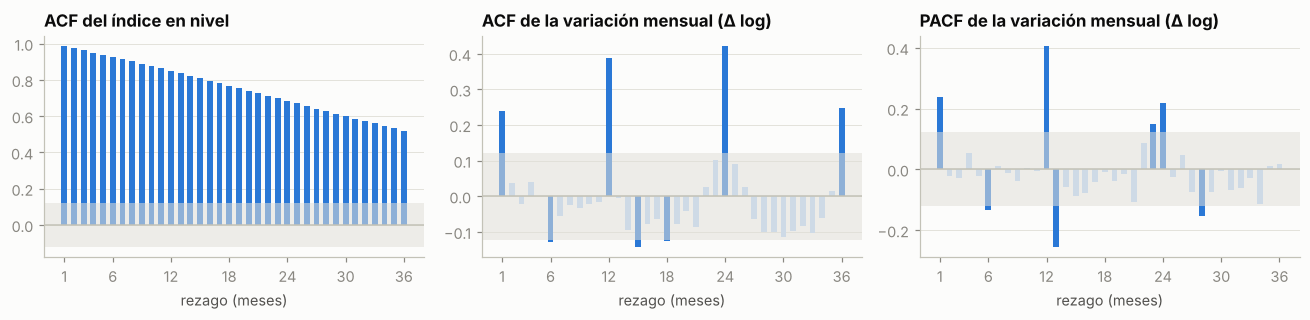

Banda de significancia (95 %): ±0.122. Barras oscuras = fuera de la banda.
ACF  significativa en rezagos: [1, 6, 12, 15, 18, 24, 36]
PACF significativa en rezagos: [1, 6, 12, 13, 23, 24, 28]
ACF(1) = 0.239 | ACF(12) = 0.387 | PACF(1) = 0.239 | PACF(2) = -0.022


In [5]:
def barras(ax, vals, n, titulo):
    k = np.arange(1, len(vals)); lim = 1.96 / np.sqrt(n)
    ax.bar(k, vals[1:], color=["#2a78d6" if abs(v) > lim else "#b7d3f6" for v in vals[1:]], width=0.6)
    ax.axhspan(-lim, lim, color="#e1e0d9", alpha=0.55, lw=0); ax.axhline(0, color="#c3c2b7", lw=1)
    ax.set(title=titulo, xlabel="rezago (meses)", xticks=[1, 6, 12, 18, 24, 30, 36]); ax.grid(axis="x", visible=False)
d1 = ly.diff().dropna(); fig, axs = plt.subplots(1, 3, figsize=(12, 3))
barras(axs[0], acf(y, nlags=36), len(y), "ACF del índice en nivel")
barras(axs[1], acf(d1, nlags=36), len(d1), "ACF de la variación mensual (Δ log)")
barras(axs[2], pacf(d1, nlags=36, method="ywm"), len(d1), "PACF de la variación mensual (Δ log)")
plt.tight_layout(); plt.show()
a, pa = acf(d1, nlags=36), pacf(d1, nlags=36, method="ywm"); lim = 1.96 / np.sqrt(len(d1))
print(f"Banda de significancia (95 %): ±{lim:.3f}. Barras oscuras = fuera de la banda.")
print("ACF  significativa en rezagos:", [k for k in range(1, 37) if abs(a[k]) > lim])
print("PACF significativa en rezagos:", [k for k in range(1, 37) if abs(pa[k]) > lim])
print(f"ACF(1) = {a[1]:.3f} | ACF(12) = {a[12]:.3f} | PACF(1) = {pa[1]:.3f} | PACF(2) = {pa[2]:.3f}")

**Lectura.**

- La ACF en nivel decae muy lento: firma clásica de una serie con tendencia.
- En la variación mensual, ACF y PACF son significativas en el rezago 1 (0.24) y la PACF del rezago 2 es prácticamente cero: eso sugiere un componente **de orden bajo, AR(1) o MA(1)**. Un mes de alza tiende a ir seguido de otro mes de alza.
- Hay picos en los rezagos 6, 12 y 24, y **la ACF del rezago 12 (0.39) es mayor que la del rezago 1**: la dependencia anual es más importante de lo que sugería la fuerza estacional de la STL. Es el escalón de enero. Se permiten términos estacionales (P, Q ≤ 1).

Candidatos: (p, 1, q)(P, 0, Q)₁₂ con p, q ≤ 2. El orden final se elige por AIC en la sección 3.

## 3. Los cuatro modelos

Todos se ajustan **solo con el entrenamiento** (hasta julio de 2024). Los últimos 12 meses se guardan para la prueba.

| Modelo | Qué captura | Parámetros |
|---|---|---|
| Suavizamiento exponencial simple | Nivel | α |
| Holt | Nivel y tendencia lineal | α, β |
| Holt-Winters | Nivel, tendencia y estacionalidad multiplicativa de 12 meses | α, β, γ |
| SARIMA sobre log(índice) | Dependencia entre meses, deriva y estacionalidad | órdenes por AIC |
| *Ingenuo y deriva* | *Referencias: "seguirá igual" y "seguirá creciendo al ritmo de los últimos 5 años"* | |

In [6]:
orden, estacional, busqueda = M.elegir_sarima(ent)
print(f"SARIMA elegido por AIC: {orden}{estacional[:3]}[12] con constante (deriva)")
display(busqueda.head(5))
ajustes = {n: M.ajustar(n, ent, (orden, estacional)) for n in M.MODELOS}
filas = []
for n in ("ses", "holt", "holt_winters", "sarima"):
    par = {k: (f"{v:.4f}" if isinstance(v, (float, np.floating)) else str(v)) for k, v in ajustes[n]["parametros"].items()}
    filas.append({"modelo": M.ETIQUETA[n], "parámetros estimados": ", ".join(f"{k} = {v}" for k, v in par.items())})
pd.set_option("display.max_colwidth", 90); display(pd.DataFrame(filas).set_index("modelo"))

SARIMA elegido por AIC: (1, 1, 0)(1, 0, 1)[12] con constante (deriva)


,orden,estacional,AIC,BIC
0,"(1, 1, 0)","(1, 0, 1)","-1,545.383","-1,527.856"
1,"(1, 1, 1)","(1, 0, 1)","-1,543.923","-1,522.891"
2,"(2, 1, 0)","(1, 0, 1)","-1,542.864","-1,521.832"
3,"(0, 1, 2)","(1, 0, 1)","-1,542.845","-1,521.813"
4,"(0, 1, 1)","(1, 0, 1)","-1,542.503","-1,524.977"


,parámetros estimados
modelo,
Suavizamiento simple,alfa = 1.0000
Holt,"alfa = 1.0000, beta = 0.0234"
Holt-Winters,"alfa = 1.0000, beta = 0.1300, gamma = 0.0000"
SARIMA,"orden = (1, 1, 0), estacional = (1, 0, 1), AIC = -1545.3831"


**Lectura de los parámetros.**

- **α ≈ 1 en los tres suavizamientos.** El modelo le cree casi por completo al último dato. Con α = 1 el suavizamiento simple se vuelve idéntico al modelo ingenuo: su pronóstico es una línea plana en el último valor. Esto es coherente con una serie que se comporta como caminata con deriva.
- **γ ≈ 0 en Holt-Winters.** El patrón estacional no se actualiza: se estima una sola vez y se queda fijo, lo esperable con estacionalidad débil y estable.
- **SARIMA** elige un AR(1) más un término estacional, lo mismo que sugerían la ACF y la PACF.

## 4. Evaluación: MAE, RMSE y MAPE

### 4.1 Retención de los últimos 12 meses

,MAE,RMSE,MAPE_pct,MAPE % (Nacional)
modelo,,,,
Holt-Winters,0.999,1.107,0.661,0.585
Holt,1.969,2.373,1.302,1.466
Ingenuo (último valor),2.380,2.887,1.564,2.268
Suavizamiento simple,2.380,2.887,1.564,2.268
SARIMA,3.369,4.060,2.216,0.491
Deriva (referencia),4.183,4.810,2.761,1.417


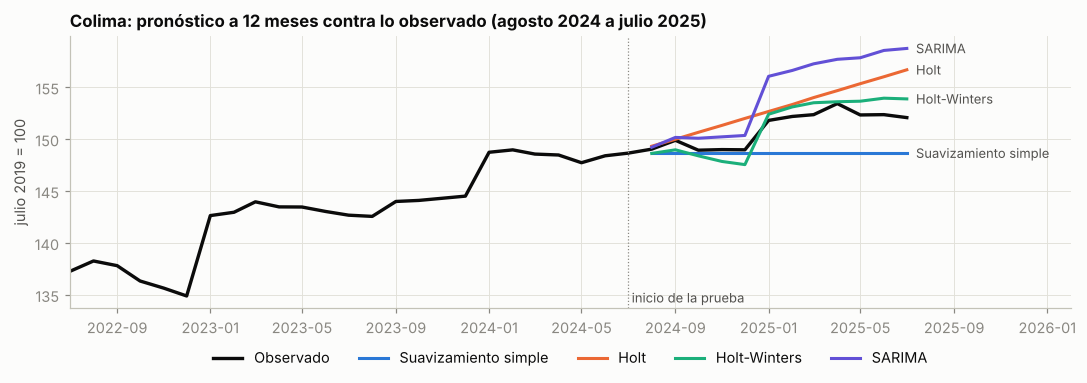

In [7]:
ret, pronos = M.evaluar_retencion(y, H, (orden, estacional))
ret_nac_orden = M.elegir_sarima(nac.iloc[:-H])[:2]; ret_nac, _ = M.evaluar_retencion(nac, H, ret_nac_orden)
t = ret.assign(modelo=ret.modelo.map(M.ETIQUETA)).set_index("modelo"); t["MAPE % (Nacional)"] = ret_nac.MAPE_pct.to_numpy()
display(t.sort_values("RMSE"))
fig, ax = plt.subplots(figsize=(10, 3.6)); ax.plot(y["2022-07-01":], color="#0b0b0b", lw=2.2, label="Observado")
ax.axvline(ent.index[-1], color="#898781", lw=0.8, ls=":"); ax.text(ent.index[-1], ax.get_ylim()[0], " inicio de la prueba", fontsize=8.5, color="#52514e", va="bottom")
for n in ("ses", "holt", "holt_winters", "sarima"):
    p = pronos[n]; ax.plot(p, color=COLOR[n], label=M.ETIQUETA[n]); ax.text(p.index[-1] + pd.Timedelta(days=12), p.iloc[-1], M.ETIQUETA[n], color="#52514e", fontsize=8.5, va="center")
ax.set(title="Colima: pronóstico a 12 meses contra lo observado (agosto 2024 a julio 2025)", ylabel="julio 2019 = 100", xlim=(pd.Timestamp("2022-07-01"), pd.Timestamp("2026-02-01")))
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1)); plt.tight_layout(); plt.show()

En esta ventana Holt-Winters es el mejor en Colima y SARIMA queda peor que el modelo ingenuo (anticipó bien el escalón de enero de 2025, pero lo exageró); en el Nacional, con el mismo procedimiento, SARIMA es el mejor. **Una sola ventana de 12 meses no alcanza para decidir**: el resultado depende de qué pasó justo en ese año (en Colima el índice se aplanó entre 2024 y 2025 y los modelos con deriva se pasaron de largo).

### 4.2 Validación con origen móvil (la que decide)

Se repite el pronóstico desde **36 fechas de origen distintas** (los últimos tres años). En cada una el modelo se reajusta solo con lo conocido hasta ese mes y se mide el error a 1, 3, 6 y 12 meses. Son 36 pronósticos por modelo y horizonte en lugar de uno.

In [8]:
vc = M.validacion_origen_movil(y, horizontes=(1, 3, 6, 12), origenes=36, sarima=(orden, estacional)); res = M.resumen_validacion(vc)
print(f"Orígenes: {vc.origen.min():%Y-%m} a {vc.origen.max():%Y-%m} | pronósticos por modelo y horizonte: {vc.groupby(['modelo', 'h']).size().iloc[0]}")
for met in ("MAE", "RMSE", "MAPE_pct"):
    t = res.pivot(index="modelo", columns="h", values=met).rename(index=M.ETIQUETA); t.columns = [f"{met.replace('_pct', ' %')} h={h}" for h in t.columns]; display(t.sort_values(t.columns[0]))
mejor = res.loc[res.groupby("h").MAPE_pct.idxmin(), ["h", "modelo", "MAPE_pct"]].assign(modelo=lambda d: d.modelo.map(M.ETIQUETA)); print("Mejor modelo por horizonte (MAPE):"); display(mejor.set_index("h"))
vc_nac = M.validacion_origen_movil(nac, horizontes=(1, 3, 6, 12), origenes=36, sarima=ret_nac_orden); res_nac = M.resumen_validacion(vc_nac)

Orígenes: 2021-08 a 2024-07 | pronósticos por modelo y horizonte: 36


,MAE h=1,MAE h=3,MAE h=6,MAE h=12
modelo,,,,
SARIMA,0.996,2.129,3.529,6.163
Ingenuo (último valor),1.201,2.903,4.482,7.108
Suavizamiento simple,1.201,2.903,4.482,7.108
Holt-Winters,1.239,2.454,3.129,5.348
Holt,1.370,3.021,4.094,5.129
Deriva (referencia),1.400,3.001,4.066,5.538


,RMSE h=1,RMSE h=3,RMSE h=6,RMSE h=12
modelo,,,,
SARIMA,1.516,2.654,4.136,6.498
Holt-Winters,1.713,2.767,3.874,6.630
Deriva (referencia),2.181,3.608,4.910,6.071
Holt,2.203,3.656,4.963,5.738
Ingenuo (último valor),2.296,4.136,6.101,7.968
Suavizamiento simple,2.296,4.136,6.101,7.968


,MAPE % h=1,MAPE % h=3,MAPE % h=6,MAPE % h=12
modelo,,,,
SARIMA,0.724,1.528,2.491,4.217
Ingenuo (último valor),0.872,2.091,3.192,4.946
Suavizamiento simple,0.872,2.091,3.192,4.946
Holt-Winters,0.892,1.748,2.213,3.691
Holt,0.991,2.168,2.917,3.520
Deriva (referencia),1.008,2.143,2.876,3.766


Mejor modelo por horizonte (MAPE):


,modelo,MAPE_pct
h,,
1,SARIMA,0.724
3,SARIMA,1.528
6,Holt-Winters,2.213
12,Holt,3.520


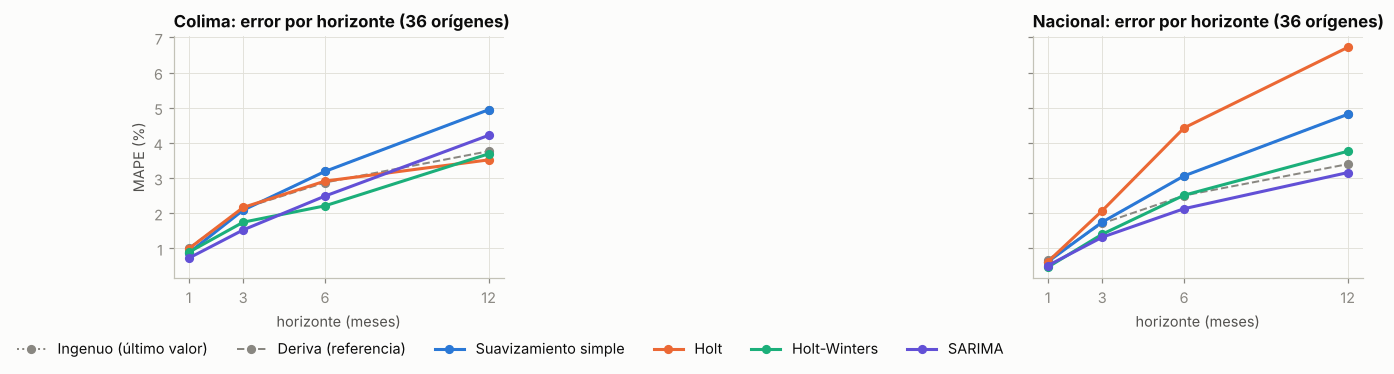

MAPE % del índice Nacional:


h,1,3,6,12
modelo,,,,
Deriva (referencia),0.681,1.715,2.506,3.398
Holt,0.621,2.076,4.429,6.718
Holt-Winters,0.468,1.407,2.515,3.764
Ingenuo (último valor),0.620,1.752,3.065,4.815
SARIMA,0.512,1.322,2.132,3.158
Suavizamiento simple,0.620,1.752,3.065,4.815


Sesgo (error medio, real - pronóstico) en Colima:


h,1,3,6,12
modelo,,,,
Deriva (referencia),-0.096,-0.446,-1.271,-4.207
Holt,-0.111,-0.475,-1.275,-3.993
Holt-Winters,-0.134,-0.572,-1.419,-4.278
Ingenuo (último valor),0.814,2.300,4.275,7.108
SARIMA,-0.095,-0.569,-1.591,-4.830
Suavizamiento simple,0.814,2.300,4.275,7.108


In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.6), sharey=True)
for ax, r, tit in ((axs[0], res, "Colima"), (axs[1], res_nac, "Nacional")):
    for n in M.MODELOS:
        d = r[r.modelo == n]; ax.plot(d.h, d.MAPE_pct, color=COLOR[n], ls=ESTILO.get(n, "-"), lw=1.3 if n in ESTILO else 2, marker="o", ms=5, label=M.ETIQUETA[n])
    ax.set(title=f"{tit}: error por horizonte (36 orígenes)", xlabel="horizonte (meses)", xticks=[1, 3, 6, 12])
axs[0].set_ylabel("MAPE (%)"); axs[0].legend(frameon=False, ncol=6, loc="upper center", bbox_to_anchor=(1.02, -0.2)); plt.tight_layout(); plt.show()
print("MAPE % del índice Nacional:"); display(res_nac.pivot(index="modelo", columns="h", values="MAPE_pct").rename(index=M.ETIQUETA))
print("Sesgo (error medio, real - pronóstico) en Colima:"); display(res.pivot(index="modelo", columns="h", values="sesgo").rename(index=M.ETIQUETA))

**Lectura.**

- **A 1 y 3 meses gana SARIMA** en Colima, con un MAPE cercano a 0.7 % a un mes y 1.5 % a tres. Es el horizonte que le sirve a quien está cotizando una obra.
- **A 6 meses gana Holt-Winters**, y a 12 meses los modelos quedan muy cerca entre sí (entre 3.5 % y 4.2 %): a un año ninguno le saca ventaja clara a la referencia de deriva.
- **El suavizamiento simple es idéntico al ingenuo** en todos los horizontes (consecuencia de α ≈ 1) y es el peor a 6 y 12 meses, porque no tiene tendencia.
- **Holt es inestable:** aceptable en Colima, pero en el Nacional es el peor a 6 y 12 meses. Extrapola como recta la tendencia reciente, y después de un choque esa recta se dispara.
- En el **Nacional** el orden se repite en lo esencial: SARIMA y Holt-Winters arriba, SARIMA mejor a 3, 6 y 12 meses.
- El error crece con el horizonte en todos los modelos, como debe ser.
- **Sesgo:** a 12 meses todos los modelos con tendencia tienen error medio negativo (pronosticaron de más, entre 4 y 5 puntos del índice). La validación cubre de 2021 a 2024, justo la desaceleración que siguió al alza de 2021 y 2022: los modelos tardan en dejar de extrapolar el ritmo alto.

## 5. Diagnóstico de residuos

Un modelo bien especificado deja residuos sin estructura: media cero y sin autocorrelación (**ruido blanco**). Se prueba con **Ljung-Box** a 12 y 24 rezagos (H0: no hay autocorrelación; se corrigen los grados de libertad por los parámetros estimados) y normalidad con Jarque-Bera. Los residuos de SARIMA están en escala logarítmica; los demás, en puntos del índice.

,n,media,desv,LB(12),p LB(12),LB(24),p LB(24),p Jarque-Bera,ruido blanco
modelo,,,,,,,,,
Ingenuo (último valor),246,0.426,1.188,106.880,0.000,172.507,0.000,0.000,False
Deriva (referencia),246,-0.116,1.174,100.584,0.000,173.219,0.000,0.000,False
Suavizamiento simple,235,0.426,1.194,110.170,0.000,173.163,0.000,0.000,False
Holt,235,0.068,1.186,105.686,0.000,175.758,0.000,0.000,False
Holt-Winters,235,0.003,0.853,52.067,0.000,79.836,0.000,0.000,False
SARIMA,245,-0.000,0.010,19.407,0.013,28.141,0.106,0.000,False


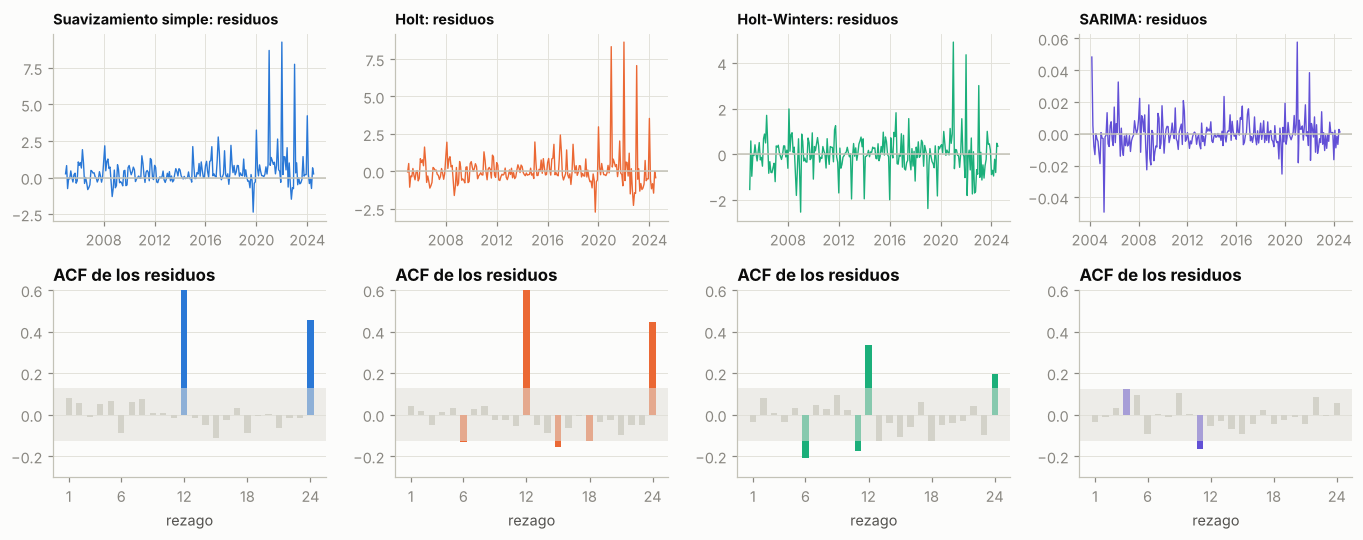

Mayores residuos de SARIMA (en %): {'2021-01': 5.8, '2005-03': 4.9, '2004-03': 4.8, '2022-01': 3.8, '2006-05': 3.3}


In [10]:
diag = pd.DataFrame([{"modelo": M.ETIQUETA[n], **M.diagnostico_residuos(ajustes[n]["residuos"], ajustes[n]["n_param"])} for n in M.MODELOS]).set_index("modelo")
display(diag)
fig, axs = plt.subplots(2, 4, figsize=(12.5, 5))
for j, n in enumerate(("ses", "holt", "holt_winters", "sarima")):
    r = ajustes[n]["residuos"]; axs[0, j].plot(r, color=COLOR[n], lw=0.9); axs[0, j].axhline(0, color="#c3c2b7", lw=1); axs[0, j].set_title(f"{M.ETIQUETA[n]}: residuos", fontsize=9.5)
    ar = acf(r, nlags=24); lim = 1.96 / np.sqrt(len(r)); k = np.arange(1, 25)
    axs[1, j].bar(k, ar[1:], color=[COLOR[n] if abs(v) > lim else "#c3c2b7" for v in ar[1:]], width=0.6); axs[1, j].axhspan(-lim, lim, color="#e1e0d9", alpha=0.55, lw=0)
    axs[1, j].set(title="ACF de los residuos", xlabel="rezago", xticks=[1, 6, 12, 18, 24], ylim=(-0.3, 0.6)); axs[1, j].title.set_fontsize(9.5); axs[1, j].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
s_res = ajustes["sarima"]["residuos"]; print("Mayores residuos de SARIMA (en %):", {f"{k:%Y-%m}": round(v * 100, 1) for k, v in s_res.abs().sort_values(ascending=False).head(5).items()})

**Lectura.**

- **Suavizamiento simple, Holt y las dos referencias fallan con claridad**: la ACF de sus residuos tiene barras enormes en los rezagos 12 y 24 (cerca de 0.6 y 0.45). Es el escalón de enero: cada año se equivocan en el mismo mes y por el mismo lado. Dejan información sin usar.
- **Holt-Winters mejora** (baja esa barra a la mitad) pero sigue rechazando Ljung-Box: su patrón estacional es fijo (γ ≈ 0) y el escalón de enero ha crecido desde 2021.
- **SARIMA es el que más se acerca al ruido blanco:** elimina la autocorrelación de los rezagos 12 y 24, solo dos barras quedan apenas fuera de la banda, y **pasa Ljung-Box a 24 rezagos**, pero **no a 12** con la corrección de grados de libertad (valor p cercano a 0.01). Con los criterios fijados antes de ver los datos, **ningún modelo cumple del todo**.
- **Ninguno tiene residuos normales** (Jarque-Bera rechaza en todos): los residuos más grandes caen en los meses de choque de precios. No es un problema del promedio del pronóstico, sino de sus intervalos, que resultan demasiado estrechos en épocas de choque.

Se buscó un SARIMA que pasara las dos pruebas ampliando p y q hasta 3 y no existe en esa familia. Lo que queda por modelar no es dependencia lineal sino **varianza que cambia en el tiempo** y **choques puntuales**; eso se atiende con variables de intervención o un modelo de volatilidad, no con más rezagos. Queda como trabajo de E2.

## 6. Pronóstico y conclusiones

,pronóstico,IC 80 % inf,IC 80 % sup,IC 95 % inf,IC 95 % sup,variación anual %
2025-08,152.428,150.495,154.386,149.481,155.433,2.274
2025-09,153.283,150.088,156.546,148.424,158.301,2.265
2025-10,153.013,148.832,157.311,146.665,159.636,2.737
2025-11,153.192,148.182,158.372,145.596,161.184,2.818
2025-12,153.342,147.616,159.290,144.672,162.532,2.933
2026-01,157.633,151.099,164.450,147.750,168.177,3.839
2026-02,158.152,151.008,165.635,147.358,169.738,3.920
2026-03,158.652,150.942,166.755,147.014,171.211,4.130
2026-04,159.309,151.061,168.007,146.869,172.802,3.834
2026-05,159.127,150.415,168.345,145.997,173.438,4.461


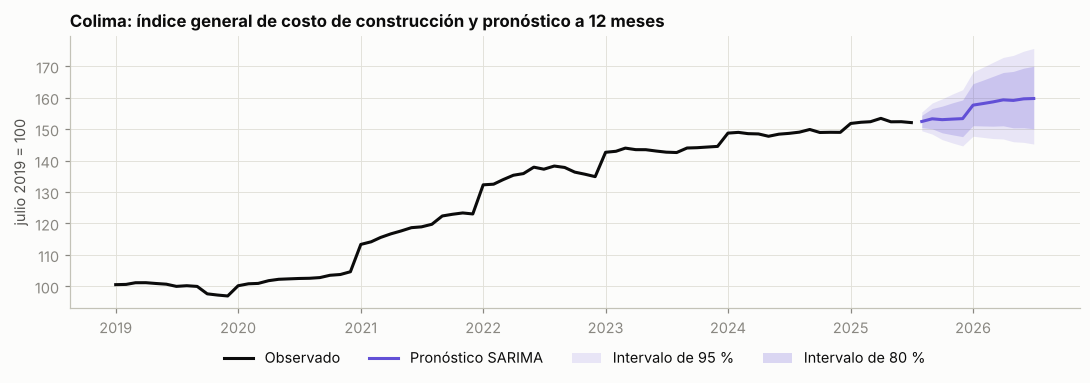

Último dato (2025-07): 152.1 | pronóstico a 12 meses (2026-07): 159.7, IC 95 % de 145.3 a 175.7


In [11]:
final = M.ajustar("sarima", y, (orden, estacional)); h = 12
p = final["pronosticar"](h); ic80 = final["intervalo"](h, 0.20); ic95 = final["intervalo"](h, 0.05)
tab = pd.DataFrame({"pronóstico": p, "IC 80 % inf": ic80.iloc[:, 0], "IC 80 % sup": ic80.iloc[:, 1], "IC 95 % inf": ic95.iloc[:, 0], "IC 95 % sup": ic95.iloc[:, 1]})
tab["variación anual %"] = (p.to_numpy() / y.iloc[-12:].to_numpy() - 1) * 100; tab.index = tab.index.strftime("%Y-%m"); display(tab)
fig, ax = plt.subplots(figsize=(10, 3.6)); ax.plot(y["2019-01-01":], color="#0b0b0b", label="Observado"); ax.plot(p, color="#6250d6", label="Pronóstico SARIMA")
ax.fill_between(p.index, ic95.iloc[:, 0], ic95.iloc[:, 1], color="#6250d6", alpha=0.13, lw=0, label="Intervalo de 95 %"); ax.fill_between(p.index, ic80.iloc[:, 0], ic80.iloc[:, 1], color="#6250d6", alpha=0.22, lw=0, label="Intervalo de 80 %")
ax.set(title="Colima: índice general de costo de construcción y pronóstico a 12 meses", ylabel="julio 2019 = 100"); ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1)); plt.tight_layout(); plt.show()
print(f"Último dato ({y.index[-1]:%Y-%m}): {y.iloc[-1]:.1f} | pronóstico a 12 meses ({p.index[-1]:%Y-%m}): {p.iloc[-1]:.1f}, IC 95 % de {ic95.iloc[-1, 0]:.1f} a {ic95.iloc[-1, 1]:.1f}")

### Conclusiones

1. **La serie no es estacionaria en nivel y sí lo es su variación mensual** (ADF y KPSS coinciden). Tiene tendencia dominante, un escalón cada enero y choques que cambian su volatilidad.
2. **Modelo elegido para ObraPrecio: SARIMA sobre el logaritmo**, por tres razones: menor error a 1 y 3 meses en la validación de 36 orígenes, residuos más cercanos al ruido blanco y, en esta implementación, es el único de los cuatro que entrega intervalos de confianza. Holt-Winters queda como modelo de contraste para 6 meses.
3. **Precisión esperada en Colima:** alrededor de 0.7 % de error a un mes, 1.5 % a tres, 2.5 % a seis y poco más de 4 % a doce.
4. **El suavizamiento simple no aporta nada sobre repetir el último valor** en esta serie, y Holt es riesgoso después de un choque.
5. **A 12 meses ningún modelo le gana con claridad a una regla simple de deriva.** El producto no debe prometer precisión a un año; el uso honesto es cotizar a 1–3 meses y dar un rango a 6–12.

### Limitaciones

- **Los residuos de SARIMA no pasan Ljung-Box a 12 rezagos** y no son normales: los intervalos mostrados son demasiado optimistas en épocas de choque de precios.
- **El pronóstico cubre agosto de 2025 a julio de 2026, meses que ya ocurrieron** pero que la estructura del índice consultada no publica. En cuanto se incorpore la estructura vigente de INEGI se podrá comparar este pronóstico contra el dato real; es la mejor prueba pendiente del modelo.
- Solo se modeló el índice general de una ciudad y el Nacional. Falta repetirlo por componente y para las 46 ciudades.
- No se usaron variables explicativas (tipo de cambio, salario mínimo). Mano de obra, que cambia por escalones, probablemente se pronostica mejor con el calendario de aumentos salariales que con un modelo de series de tiempo.